In [4]:
!pip install rasterio matplotlib numpy torch torchvision

In [5]:
import os
import rasterio
import numpy as np
import matplotlib.pyplot as plt

In [6]:
s1_folder = "/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/S1Hand/S1Hand"
label_folder = "/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/LabelHand/LabelHand"

image_name = "Bolivia_103757_S1Hand.tif"
label_name = "Bolivia_103757_LabelHand.tif"

image_path = os.path.join(s1_folder, image_name)
label_path = os.path.join(label_folder, label_name)

len(image_name)

25

In [7]:
### dataset info
with rasterio.open(image_path) as src:
    print("file:",image_name[0])
    print("width:",src.width)
    print("height:",src.height)
    print("no.of bands:",src.count)
    print("data type:",src.dtypes)
    
    
    image = src.read()
    print("Image shape:", image.shape)
    print("Minimum value:", image.min())
    print("Maximum value:", image.max())
    for i in range(src.count):
        print(f"Band {i+1}:")
        print("  Min:", image[i].min())
        print("  Max:", image[i].max())
        print("  Mean:", image[i].mean())

file: B
width: 512
height: 512
no.of bands: 2
data type: ('float32', 'float32')
Image shape: (2, 512, 512)
Minimum value: nan
Maximum value: nan
Band 1:
  Min: nan
  Max: nan
  Mean: nan
Band 2:
  Min: nan
  Max: nan
  Mean: nan


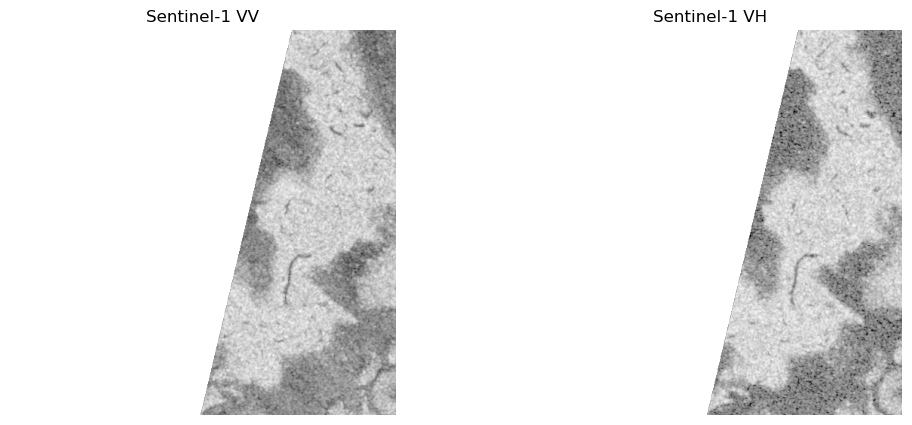

In [8]:
### vv and vh representation
import matplotlib.pyplot as plt

with rasterio.open(image_path) as src:
    vv = src.read(1)
    vh = src.read(2)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(vv, cmap="gray")
plt.title("Sentinel-1 VV")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(vh, cmap="gray")
plt.title("Sentinel-1 VH")
plt.axis("off")

plt.show()

In [9]:
with rasterio.open(label_path) as src:
    label = src.read(1)

print("Label shape:", label.shape)
print("Label data type:", label.dtype)
print("Unique label values:", np.unique(label))

Label shape: (512, 512)
Label data type: int16
Unique label values: [-1  0  1]


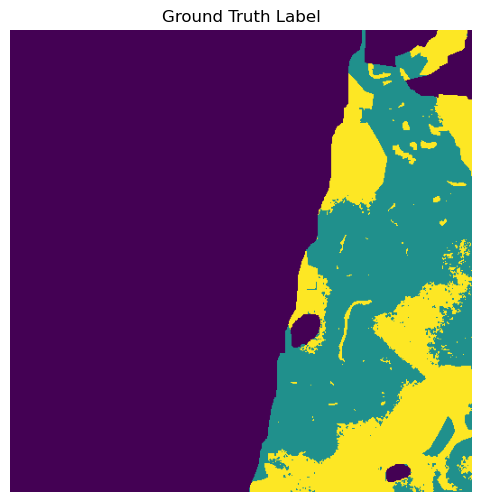

In [10]:
### Ground-Truth Label Inspection
plt.figure(figsize=(6, 6))

plt.imshow(label)
plt.title("Ground Truth Label")
plt.axis("off")

plt.show()

In [11]:
import os
import rasterio
import numpy as np
jrc_folder = "/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/JRCWaterHand/JRCWaterHand"

jrc_name = "Bolivia_129334_JRCWaterHand.tif"
jrc_path = os.path.join(jrc_folder, jrc_name)

with rasterio.open(jrc_path) as src:
    jrc = src.read(1)

print("JRC shape:", jrc.shape)
print("JRC pixels with permanent water:", np.sum(jrc == 1))
print("JRC water percentage:", np.sum(jrc == 1) / jrc.size * 100)

JRC shape: (512, 512)
JRC pixels with permanent water: 4152
JRC water percentage: 1.5838623046875


In [12]:
import os
import rasterio
import numpy as np

jrc_files = os.listdir(jrc_folder)

print("Total JRC files:", len(jrc_files))

for file in jrc_files[:10]:
    path = os.path.join(jrc_folder, file)
    with rasterio.open(path) as src:
        data = src.read(1)
        print(file, np.unique(data))

Total JRC files: 446
Spain_4282030_JRCWaterHand.tif [0 1]
Mekong_846007_JRCWaterHand.tif [0]
India_570384_JRCWaterHand.tif [0 1]
India_164336_JRCWaterHand.tif [0]
India_135434_JRCWaterHand.tif [0 1]
USA_664261_JRCWaterHand.tif [0 1]
Paraguay_892933_JRCWaterHand.tif [0]
Pakistan_35915_JRCWaterHand.tif [0 1]
Sri-Lanka_132922_JRCWaterHand.tif [0 1]
Bolivia_379434_JRCWaterHand.tif [0]


In [13]:
print("JRC unique values:", np.unique(jrc))
print("Number of pixels:", jrc.size)
print("Number of JRC water pixels:", np.sum(jrc == 1))

JRC unique values: [0 1]
Number of pixels: 262144
Number of JRC water pixels: 4152


In [14]:
label_name = "Bolivia_129334_LabelHand.tif"
label_path = os.path.join(label_folder, label_name)

with rasterio.open(label_path) as src:
    label = src.read(1)

print("Label values:", np.unique(label))

print("Label water pixels:", np.sum(label == 1))
print("Permanent water pixels:", np.sum(jrc == 1))

overlap = np.sum((label == 1) & (jrc == 1))

print("Water + permanent water overlap:", overlap)

Label values: [-1  0  1]
Label water pixels: 156643
Permanent water pixels: 4152
Water + permanent water overlap: 3994


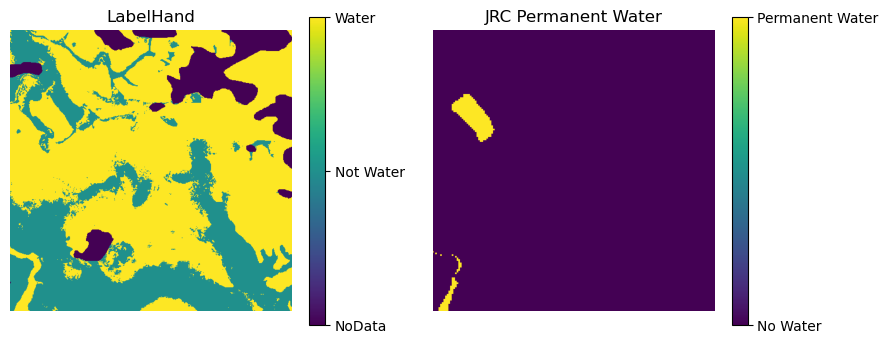

In [15]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(label)
plt.title("LabelHand")
plt.axis("off")
c = plt.colorbar()
c.set_ticks([-1, 0, 1])
c.set_ticklabels(["NoData", "Not Water", "Water"])

plt.subplot(1, 2, 2)
plt.imshow(jrc)
plt.title("JRC Permanent Water")
plt.axis("off")
c = plt.colorbar()
c.set_ticks([0, 1])
c.set_ticklabels(["No Water", "Permanent Water"])

plt.show()

In [16]:
# label == 0 → Land 
# label == 1 → temporarily called Flooded Land (2) 
# label == 1 AND jrc == 1 → changed to Permanent Water (1) 

three_class = np.zeros_like(label, dtype=np.uint8)

three_class[label == 1] = 2
three_class[(label == 1) & (jrc == 1)] = 1

In [17]:
# ignore classes with -1
three_class[label == -1] = 255

print("Final values:", np.unique(three_class))

Final values: [  0   1   2 255]


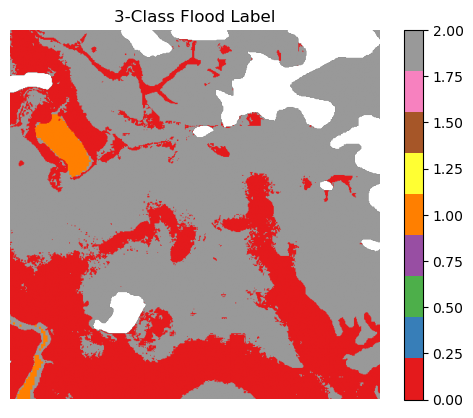

In [18]:
plt.imshow(np.ma.masked_equal(three_class, 255), cmap="Set1", vmin=0, vmax=2)
plt.title("3-Class Flood Label")
plt.colorbar()
plt.axis("off")
plt.show()

In [19]:
for value in [0, 1, 2, 255]:
    print(value, ":", np.sum(three_class == value))

0 : 81171
1 : 3994
2 : 152649
255 : 24330


In [20]:
total = np.sum(three_class != 255)

for value, name in [(0, "Land"), (1, "Permanent Water"), (2, "Flooded Land")]:
    count = np.sum(three_class == value)
    print(name, ":", count, "pixels,", round(count / total * 100, 2), "%")

Land : 81171 pixels, 34.13 %
Permanent Water : 3994 pixels, 1.68 %
Flooded Land : 152649 pixels, 64.19 %


In [21]:
print("VV - valid pixels:", np.sum(np.isfinite(vv)))
print("VV - total pixels:", vv.size)

print("VH - valid pixels:", np.sum(np.isfinite(vh)))
print("VH - total pixels:", vh.size)

print("\nVV - NaN pixels:", np.sum(np.isnan(vv)))
print("VH - NaN pixels:", np.sum(np.isnan(vh)))

VV - valid pixels: 101623
VV - total pixels: 262144
VH - valid pixels: 101623
VH - total pixels: 262144

VV - NaN pixels: 160521
VH - NaN pixels: 160521


In [22]:
### preprocessing
print("VV NaN pixels:", np.isnan(vv).sum())
print("VH NaN pixels:", np.isnan(vh).sum())

VV NaN pixels: 160521
VH NaN pixels: 160521


In [23]:
vv.shape

(512, 512)

In [24]:
print("Label NoData:", np.sum(label == -1))
print("S1 VV NoData:", np.isnan(vv).sum())

Label NoData: 24330
S1 VV NoData: 160521


In [25]:
nodata_mask = np.isnan(vv) | np.isnan(vh) | (label == -1)

print("Total pixels to ignore:", nodata_mask.sum())

Total pixels to ignore: 173901


In [26]:
vv_min, vv_max = np.nanmin(vv), np.nanmax(vv)
vh_min, vh_max = np.nanmin(vh), np.nanmax(vh)

vv_norm = (vv - vv_min) / (vv_max - vv_min)
vh_norm = (vh - vh_min) / (vh_max - vh_min)

# minimum value of an array while ignoring any NaN
print("VV range:", np.nanmin(vv_norm), np.nanmax(vv_norm))
print("VH range:", np.nanmin(vh_norm), np.nanmax(vh_norm))

VV range: 0.0 1.0
VH range: 0.0 1.0


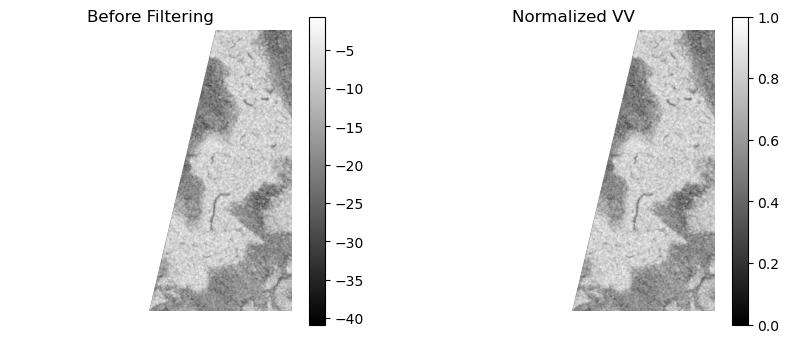

In [27]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(vv, cmap="gray")
plt.colorbar()
plt.title("Before Filtering")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(vv_norm, cmap="gray")
plt.title("Normalized VV")
plt.colorbar()
plt.axis("off")
plt.show()

In [28]:
vv_temp = np.nan_to_num(vv_norm, nan=0)
vh_temp = np.nan_to_num(vh_norm, nan=0)

In [29]:
from scipy.ndimage import median_filter

vv_filtered = median_filter(vv_temp, size=3)
vh_filtered = median_filter(vh_temp, size=3)

print("VV filtering done")
print("VH filtering done")

VV filtering done
VH filtering done


In [30]:
vv_filtered[nodata_mask] = np.nan
vh_filtered[nodata_mask] = np.nan

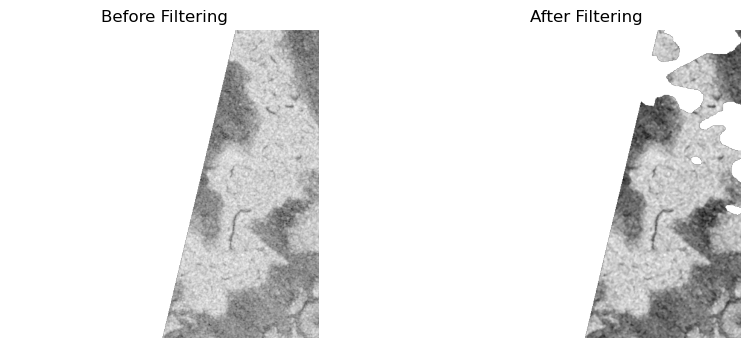

In [31]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(vv_norm, cmap="gray")
plt.title("Before Filtering")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(vv_filtered, cmap="gray")
plt.title("After Filtering")
plt.axis("off")

plt.show()

In [32]:
s1_input = np.stack([vv_filtered, vh_filtered], axis=0)
print("S1 input shape:", s1_input.shape)

S1 input shape: (2, 512, 512)


In [33]:
import pandas as pd
import os


In [34]:
split_folder = "/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/splits/splits/flood_handlabeled"

In [35]:
train_df = pd.read_csv(os.path.join(split_folder, "flood_train_data.csv"))
valid_df = pd.read_csv(os.path.join(split_folder, "flood_valid_data.csv"))
test_df = pd.read_csv(os.path.join(split_folder, "flood_test_data.csv"))

In [36]:
print("Train:", len(train_df))
print("Validation:", len(valid_df))
print("Test:", len(test_df))


Train: 251
Validation: 88
Test: 89


In [37]:
print("\nColumns:")
print(train_df.columns.tolist())


Columns:
['Ghana_103272_S1Hand.tif', 'Ghana_103272_LabelHand.tif']


In [38]:
import rasterio
import numpy as np
import os



In [39]:
s1_folder = "/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/S1Hand/S1Hand"

In [40]:
vv_min = np.inf
vv_max = -np.inf
vh_min = np.inf
vh_max = -np.inf

for filename in train_df.columns:
    if filename.endswith("_S1Hand.tif"):
        path = os.path.join(s1_folder, filename)

        with rasterio.open(path) as src:
            vv = src.read(1)
            vh = src.read(2)

        vv_valid = vv[np.isfinite(vv)]
        vh_valid = vh[np.isfinite(vh)]

        if len(vv_valid) > 0:
            vv_min = min(vv_min, vv_valid.min())
            vv_max = max(vv_max, vv_valid.max())

        if len(vh_valid) > 0:
            vh_min = min(vh_min, vh_valid.min())
            vh_max = max(vh_max, vh_valid.max())

print("Global VV range:", vv_min, "to", vv_max)
print("Global VH range:", vh_min, "to", vh_max)


Global VV range: -39.311333 to 8.5869255
Global VH range: -47.37703 to -1.3846467


In [41]:
from scipy.ndimage import median_filter

def preprocess_s1(path):

    with rasterio.open(path) as src:
        vv = src.read(1).astype(np.float32)
        vh = src.read(2).astype(np.float32)

    # NoData mask
    nodata_mask = np.isnan(vv) | np.isnan(vh)

    # Global normalization
    vv_norm = (vv - vv_min) / (vv_max - vv_min)
    vh_norm = (vh - vh_min) / (vh_max - vh_min)

    # Replace NaN with 0 before filtering
    vv_temp = np.nan_to_num(vv_norm, nan=0.0)
    vh_temp = np.nan_to_num(vh_norm, nan=0.0)

    # 3x3 median filtering
    vv_filtered = median_filter(vv_temp, size=3)
    vh_filtered = median_filter(vh_temp, size=3)

    # Keep NoData pixels as 0 in the INPUT image
    vv_filtered[nodata_mask] = 0.0
    vh_filtered[nodata_mask] = 0.0

    # Stack VV + VH
    s1_input = np.stack(
        [vv_filtered, vh_filtered],
        axis=0
    )

    return s1_input

In [42]:
sample_filename = train_df.iloc[0, 0]
sample_path = os.path.join(s1_folder, sample_filename)

sample_input = preprocess_s1(sample_path)

print("File:", sample_filename)
print("Shape:", sample_input.shape)
print("VV range:", np.nanmin(sample_input[0]), "to", np.nanmax(sample_input[0]))
print("VH range:", np.nanmin(sample_input[1]), "to", np.nanmax(sample_input[1]))

File: Ghana_24858_S1Hand.tif
Shape: (2, 512, 512)
VV range: 0.4421506 to 0.8151716
VH range: 0.48943076 to 0.862801


In [43]:
import rasterio
import numpy as np
import os

label_folder = r"/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/LabelHand/LabelHand"
jrc_folder = r"/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/JRCWaterHand/JRCWaterHand"


In [44]:
def make_three_class_label(label_path, jrc_path):
    with rasterio.open(label_path) as src:
        label = src.read(1)

    with rasterio.open(jrc_path) as src:
        jrc = src.read(1)

    three_class = np.zeros_like(label, dtype=np.uint8)

    # Water → initially Flooded Land
    three_class[label == 1] = 2

    # Water + JRC permanent water → Permanent Water
    three_class[(label == 1) & (jrc == 1)] = 1

    # Label NoData
    three_class[label == -1] = 255

    return three_class

In [45]:
def class_distribution(df):
    counts = {0: 0, 1: 0, 2: 0, 255: 0}

    for filename in df.columns:
        if filename.endswith("_LabelHand.tif"):

            label_path = os.path.join(label_folder, filename)
            jrc_filename = filename.replace(
                "_LabelHand.tif",
                "_JRCWaterHand.tif"
            )
            jrc_path = os.path.join(jrc_folder, jrc_filename)

            three_class = make_three_class_label(label_path, jrc_path)

            for value in counts:
                counts[value] += np.sum(three_class == value)

    return counts

In [46]:
train_counts = class_distribution(train_df)
valid_counts = class_distribution(valid_df)
test_counts = class_distribution(test_df)

print("Train:", train_counts)
print("Validation:", valid_counts)
print("Test:", test_counts)

Train: {0: np.int64(257711), 1: np.int64(375), 2: np.int64(1183), 255: np.int64(2875)}
Validation: {0: np.int64(0), 1: np.int64(0), 2: np.int64(0), 255: np.int64(262144)}
Test: {0: np.int64(229531), 1: np.int64(0), 2: np.int64(14933), 255: np.int64(17680)}


In [47]:
train_df = pd.read_csv(
    os.path.join(split_folder, "flood_train_data.csv"),
    header=None,
    names=["s1", "label"]
)

valid_df = pd.read_csv(
    os.path.join(split_folder, "flood_valid_data.csv"),
    header=None,
    names=["s1", "label"]
)

test_df = pd.read_csv(
    os.path.join(split_folder, "flood_test_data.csv"),
    header=None,
    names=["s1", "label"]
)

In [48]:
print("Train:", len(train_df))
print("Validation:", len(valid_df))
print("Test:", len(test_df))

print(train_df.head())

Train: 252
Validation: 89
Test: 90
                        s1                       label
0  Ghana_103272_S1Hand.tif  Ghana_103272_LabelHand.tif
1   Ghana_24858_S1Hand.tif   Ghana_24858_LabelHand.tif
2  Ghana_147015_S1Hand.tif  Ghana_147015_LabelHand.tif
3  Ghana_953791_S1Hand.tif  Ghana_953791_LabelHand.tif
4  Ghana_154838_S1Hand.tif  Ghana_154838_LabelHand.tif


In [49]:
import os

s1_dir = r"/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/S1Hand/S1Hand"

print(s1_dir)

/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/S1Hand/S1Hand


In [50]:
vv_min, vv_max = np.inf, -np.inf
vh_min, vh_max = np.inf, -np.inf

for filename in train_df["s1"]:
    path = os.path.join(s1_dir, filename)

    with rasterio.open(path) as src:
        vv = src.read(1)
        vh = src.read(2)

    vv_valid = vv[~np.isnan(vv)]
    vh_valid = vh[~np.isnan(vh)]

    vv_min = min(vv_min, vv_valid.min())
    vv_max = max(vv_max, vv_valid.max())

    vh_min = min(vh_min, vh_valid.min())
    vh_max = max(vh_max, vh_valid.max())

print("VV:", vv_min, "to", vv_max)
print("VH:", vh_min, "to", vh_max)

VV: -65.45004 to 29.926394
VH: -79.161446 to 17.376385


In [51]:
label_dir = r"/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/LabelHand/LabelHand"
jrc_dir = r"/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/JRCWaterHand/JRCWaterHand"

In [52]:
def class_distribution(df):
    counts = {0: 0, 1: 0, 2: 0, 255: 0}

    for label_filename in df["label"]:
        label_path = os.path.join(label_dir, label_filename)

        # Corresponding JRC filename
        jrc_filename = label_filename.replace(
            "_LabelHand.tif",
            "_JRCWaterHand.tif"
        )
        jrc_path = os.path.join(jrc_dir, jrc_filename)

        with rasterio.open(label_path) as src:
            label = src.read(1)

        with rasterio.open(jrc_path) as src:
            jrc = src.read(1)

        three_class = np.zeros_like(label, dtype=np.uint8)

        # Flooded land
        three_class[label == 1] = 2

        # Permanent water
        three_class[(label == 1) & (jrc == 1)] = 1

        # NoData
        three_class[label == -1] = 255

        for cls in counts:
            counts[cls] += np.sum(three_class == cls)

    return counts

In [53]:
train_counts = class_distribution(train_df)
valid_counts = class_distribution(valid_df)
test_counts = class_distribution(test_df)

print("Train:", train_counts)
print("Validation:", valid_counts)
print("Test:", test_counts)

Train: {0: np.int64(51856372), 1: np.int64(1521824), 2: np.int64(3925211), 255: np.int64(8756881)}
Validation: {0: np.int64(18057120), 1: np.int64(611055), 2: np.int64(1626550), 255: np.int64(3036091)}
Test: {0: np.int64(17951266), 1: np.int64(899398), 2: np.int64(1666703), 255: np.int64(3075593)}


In [54]:
def class_percentages(counts):

    valid_total = counts[0] + counts[1] + counts[2]

    return {
        "Land": counts[0] / valid_total * 100,
        "Permanent Water": counts[1] / valid_total * 100,
        "Flooded Land": counts[2] / valid_total * 100
    }

print("Train:", class_percentages(train_counts))
print("Validation:", class_percentages(valid_counts))
print("Test:", class_percentages(test_counts))

Train: {'Land': np.float64(90.49439590912979), 'Permanent Water': np.float64(2.655730400113906), 'Flooded Land': np.float64(6.849873690756294)}
Validation: {'Land': np.float64(88.97445025739447), 'Permanent Water': np.float64(3.0109055431891787), 'Flooded Land': np.float64(8.01464419941635)}
Test: {'Land': np.float64(87.49302968553421), 'Permanent Water': np.float64(4.383593664820637), 'Flooded Land': np.float64(8.123376649645152)}


In [56]:
import numpy as np
import os

tile_stats = []

for idx, row in train_df.iterrows():

    label_filename = row["label"]

    label_path = os.path.join(
        label_folder,
        label_filename
    )

    jrc_filename = label_filename.replace(
        "_LabelHand.tif",
        "_JRCWaterHand.tif"
    )

    jrc_path = os.path.join(
        jrc_folder,
        jrc_filename
    )

    # Create 3-class label
    three_class = make_three_class_label(
        label_path,
        jrc_path
    )

    # Ignore NoData
    valid_pixels = three_class != 255

    total = np.sum(valid_pixels)

    land = np.sum(three_class == 0)
    permanent_water = np.sum(three_class == 1)
    flooded_land = np.sum(three_class == 2)

    tile_stats.append({
        "filename": label_filename,
        "land_pct": land / total * 100,
        "permanent_water_pct": permanent_water / total * 100,
        "flooded_land_pct": flooded_land / total * 100
    })

print("Number of training tiles:", len(tile_stats))

print("\nFirst 10 tiles:")
for item in tile_stats[:10]:
    print(item)

/var/folders/n2/zsmb8b6x5l99f4xjqnvgzc6w0000gn/T/ipykernel_39254/2949539770.py:42: RuntimeWarning: invalid value encountered in scalar divide
  "land_pct": land / total * 100,
/var/folders/n2/zsmb8b6x5l99f4xjqnvgzc6w0000gn/T/ipykernel_39254/2949539770.py:43: RuntimeWarning: invalid value encountered in scalar divide
  "permanent_water_pct": permanent_water / total * 100,
/var/folders/n2/zsmb8b6x5l99f4xjqnvgzc6w0000gn/T/ipykernel_39254/2949539770.py:44: RuntimeWarning: invalid value encountered in scalar divide
  "flooded_land_pct": flooded_land / total * 100


Number of training tiles: 252

First 10 tiles:
{'filename': 'Ghana_103272_LabelHand.tif', 'land_pct': np.float64(99.3990797202905), 'permanent_water_pct': np.float64(0.1446374229082536), 'flooded_land_pct': np.float64(0.4562828568012373)}
{'filename': 'Ghana_24858_LabelHand.tif', 'land_pct': np.float64(99.81536865234375), 'permanent_water_pct': np.float64(0.0), 'flooded_land_pct': np.float64(0.18463134765625)}
{'filename': 'Ghana_147015_LabelHand.tif', 'land_pct': np.float64(98.65341186523438), 'permanent_water_pct': np.float64(0.0), 'flooded_land_pct': np.float64(1.346588134765625)}
{'filename': 'Ghana_953791_LabelHand.tif', 'land_pct': np.float64(98.94256591796875), 'permanent_water_pct': np.float64(0.0), 'flooded_land_pct': np.float64(1.05743408203125)}
{'filename': 'Ghana_154838_LabelHand.tif', 'land_pct': np.float64(100.0), 'permanent_water_pct': np.float64(0.0), 'flooded_land_pct': np.float64(0.0)}
{'filename': 'Ghana_134751_LabelHand.tif', 'land_pct': np.float64(100.0), 'permane

In [57]:
# ============================================
# STEP 2: SUMMARIZE TRAINING TILE TYPES
# ============================================

land_only = 0
flood_tiles = 0
water_tiles = 0
both_minority = 0
empty_tiles = 0

for item in tile_stats:

    water = item["permanent_water_pct"]
    flood = item["flooded_land_pct"]

    # Completely invalid / empty tile
    if np.isnan(water) or np.isnan(flood):
        empty_tiles += 1

    # Contains both minority classes
    elif water > 0 and flood > 0:
        both_minority += 1

    # Contains permanent water
    elif water > 0:
        water_tiles += 1

    # Contains flooded land
    elif flood > 0:
        flood_tiles += 1

    # Only land
    else:
        land_only += 1


print("================================")
print("TRAINING TILE SUMMARY")
print("================================")

print("Total tiles:", len(tile_stats))
print("Land-only tiles:", land_only)
print("Flood-containing tiles:", flood_tiles)
print("Permanent-water tiles:", water_tiles)
print("Both minority classes:", both_minority)
print("Empty/invalid tiles:", empty_tiles)

TRAINING TILE SUMMARY
Total tiles: 252
Land-only tiles: 32
Flood-containing tiles: 98
Permanent-water tiles: 0
Both minority classes: 121
Empty/invalid tiles: 1


In [58]:
# ============================================
# STEP 3: MINORITY CLASS DISTRIBUTION
# ============================================

water_percentages = []
flood_percentages = []

for item in tile_stats:

    water = item["permanent_water_pct"]
    flood = item["flooded_land_pct"]

    if not np.isnan(water):
        water_percentages.append(water)

    if not np.isnan(flood):
        flood_percentages.append(flood)


print("================================")
print("MINORITY CLASS DISTRIBUTION")
print("================================")

print("\nPermanent Water:")
print("Average :", np.mean(water_percentages), "%")
print("Median  :", np.median(water_percentages), "%")
print("Maximum :", np.max(water_percentages), "%")

print("\nFlooded Land:")
print("Average :", np.mean(flood_percentages), "%")
print("Median  :", np.median(flood_percentages), "%")
print("Maximum :", np.max(flood_percentages), "%")

MINORITY CLASS DISTRIBUTION

Permanent Water:
Average : 2.631178206448873 %
Median  : 0.0 %
Maximum : 97.09002400750961 %

Flooded Land:
Average : 6.747253376489373 %
Median  : 1.848602294921875 %
Maximum : 84.20372009277344 %


In [59]:
# ============================================
# STEP 4: COUNT MINORITY-RICH TILES
# ============================================

water_1 = 0
water_5 = 0
flood_1 = 0
flood_5 = 0
both_5 = 0

for item in tile_stats:

    water = item["permanent_water_pct"]
    flood = item["flooded_land_pct"]

    if water >= 1:
        water_1 += 1

    if water >= 5:
        water_5 += 1

    if flood >= 1:
        flood_1 += 1

    if flood >= 5:
        flood_5 += 1

    if water >= 5 and flood >= 5:
        both_5 += 1


print("================================")
print("MINORITY-RICH TILE COUNTS")
print("================================")

print("Permanent Water >= 1% :", water_1)
print("Permanent Water >= 5% :", water_5)

print("Flooded Land >= 1%    :", flood_1)
print("Flooded Land >= 5%    :", flood_5)

print("Both >= 5%            :", both_5)

MINORITY-RICH TILE COUNTS
Permanent Water >= 1% : 45
Permanent Water >= 5% : 26
Flooded Land >= 1%    : 155
Flooded Land >= 5%    : 80
Both >= 5%            : 15


In [60]:
# ============================================
# STEP 5: ESTIMATE AUGMENTED DATASET SIZE
# ============================================

total_samples = 0

for item in tile_stats:

    water = item["permanent_water_pct"]
    flood = item["flooded_land_pct"]

    if water >= 5:
        multiplier = 5       # original + 4 augmentations

    elif flood >= 5:
        multiplier = 3       # original + 2 augmentations

    else:
        multiplier = 1       # original only

    total_samples += multiplier

print("================================")
print("AUGMENTATION SIZE ESTIMATE")
print("================================")
print("Original training tiles :", len(tile_stats))
print("Estimated final samples :", total_samples)
print("Additional samples      :", total_samples - len(tile_stats))

AUGMENTATION SIZE ESTIMATE
Original training tiles : 252
Estimated final samples : 486
Additional samples      : 234


In [62]:
from pathlib import Path
import os
import numpy as np

BASE_DIR = Path.home() / "Desktop" / "Sen1Floods11" / "v1.1"

aug_image_dir = os.path.join(BASE_DIR, "Augmented_S1")
aug_label_dir = os.path.join(BASE_DIR, "Augmented_Labels")

os.makedirs(aug_image_dir, exist_ok=True)
os.makedirs(aug_label_dir, exist_ok=True)

print("Augmented image folder:", aug_image_dir)
print("Augmented label folder:", aug_label_dir)

Augmented image folder: /Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/Augmented_S1
Augmented label folder: /Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/Augmented_Labels


In [63]:
# ============================================
# STEP 6: ACTUAL CLASS-AWARE AUGMENTATION
# ============================================

def apply_augmentation(image, label, aug_name):

    if aug_name == "horizontal_flip":
        image_aug = np.flip(image, axis=2)
        label_aug = np.flip(label, axis=1)

    elif aug_name == "vertical_flip":
        image_aug = np.flip(image, axis=1)
        label_aug = np.flip(label, axis=0)

    elif aug_name == "rotate_90":
        image_aug = np.rot90(image, k=1, axes=(1, 2))
        label_aug = np.rot90(label, k=1)

    elif aug_name == "rotate_180":
        image_aug = np.rot90(image, k=2, axes=(1, 2))
        label_aug = np.rot90(label, k=2)

    else:
        raise ValueError("Unknown augmentation")

    return image_aug.copy(), label_aug.copy()


created = 0

for item in tile_stats:

    label_filename = item["filename"]

    image_filename = label_filename.replace(
        "_LabelHand.tif",
        "_S1Hand.tif"
    )

    image_path = os.path.join(
        s1_folder,
        image_filename
    )

    label_path = os.path.join(
        label_folder,
        label_filename
    )

    # JRC water file
    jrc_filename = label_filename.replace(
        "_LabelHand.tif",
        "_JRCWaterHand.tif"
    )

    jrc_path = os.path.join(
        jrc_folder,
        jrc_filename
    )

    # Preprocess image
    image = preprocess_s1(image_path)

    # Create 3-class label
    label = make_three_class_label(
        label_path,
        jrc_path
    )

    water = item["permanent_water_pct"]
    flood = item["flooded_land_pct"]

    # Class-aware augmentation
    if water >= 5:
        selected_augs = [
            "horizontal_flip",
            "vertical_flip",
            "rotate_90",
            "rotate_180"
        ]

    elif flood >= 5:
        selected_augs = [
            "horizontal_flip",
            "vertical_flip"
        ]

    else:
        selected_augs = []

    base_name = label_filename.replace(
        "_LabelHand.tif",
        ""
    )

    for aug_name in selected_augs:

        aug_image, aug_label = apply_augmentation(
            image,
            label,
            aug_name
        )

        image_out = os.path.join(
            aug_image_dir,
            f"{base_name}_{aug_name}.npy"
        )

        label_out = os.path.join(
            aug_label_dir,
            f"{base_name}_{aug_name}.npy"
        )

        np.save(image_out, aug_image)
        np.save(label_out, aug_label)

        created += 1


print("================================")
print("DATA AUGMENTATION COMPLETED")
print("================================")
print("Original training tiles :", len(tile_stats))
print("New augmented samples   :", created)
print("Final training samples  :", len(tile_stats) + created)

DATA AUGMENTATION COMPLETED
Original training tiles : 252
New augmented samples   : 234
Final training samples  : 486


In [64]:
import os

print("Augmented images:", len(os.listdir(aug_image_dir)))
print("Augmented labels:", len(os.listdir(aug_label_dir)))

print("\nSample augmented images:")
print(os.listdir(aug_image_dir)[:5])

print("\nSample augmented labels:")
print(os.listdir(aug_label_dir)[:5])

Augmented images: 234
Augmented labels: 234

Sample augmented images:
['India_566697_horizontal_flip.npy', 'Mekong_774566_rotate_90.npy', 'Sri-Lanka_1038087_vertical_flip.npy', 'Mekong_1395593_vertical_flip.npy', 'Sri-Lanka_14484_vertical_flip.npy']

Sample augmented labels:
['India_566697_horizontal_flip.npy', 'Mekong_774566_rotate_90.npy', 'Sri-Lanka_1038087_vertical_flip.npy', 'Mekong_1395593_vertical_flip.npy', 'Sri-Lanka_14484_vertical_flip.npy']


In [68]:
print("Original S1 folder:", s1_folder)
print("Original label folder:", label_folder)
print("Augmented S1 folder:", aug_image_dir)
print("Augmented label folder:", aug_label_dir)

Original S1 folder: /Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/S1Hand/S1Hand
Original label folder: /Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/LabelHand/LabelHand
Augmented S1 folder: /Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/Augmented_S1
Augmented label folder: /Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/Augmented_Labels


In [70]:
from torch.utils.data import Dataset
import numpy as np
import os
import torch


class AugmentedFloodDataset(Dataset):

    def __init__(
        self,
        train_df,
        s1_folder,
        label_folder,
        jrc_folder,
        augmented_image_dir,
        augmented_label_dir
    ):

        self.samples = []

        # ==========================================
        # 1. ORIGINAL TRAINING SAMPLES
        # ==========================================

        for i in range(len(train_df)):

            s1_filename = train_df.iloc[i]["s1"]
            label_filename = train_df.iloc[i]["label"]

            s1_path = os.path.join(
                s1_folder,
                s1_filename
            )

            label_path = os.path.join(
                label_folder,
                label_filename
            )

            jrc_filename = label_filename.replace(
                "_LabelHand.tif",
                "_JRCWaterHand.tif"
            )

            jrc_path = os.path.join(
                jrc_folder,
                jrc_filename
            )

            self.samples.append(
                (
                    "original",
                    s1_path,
                    label_path,
                    jrc_path
                )
            )

        # ==========================================
        # 2. AUGMENTED TRAINING SAMPLES
        # ==========================================

        for filename in os.listdir(augmented_image_dir):

            if filename.endswith(".npy"):

                image_path = os.path.join(
                    augmented_image_dir,
                    filename
                )

                label_path = os.path.join(
                    augmented_label_dir,
                    filename
                )

                if os.path.exists(label_path):

                    self.samples.append(
                        (
                            "augmented",
                            image_path,
                            label_path,
                            None
                        )
                    )

    # ==========================================
    # NUMBER OF SAMPLES
    # ==========================================

    def __len__(self):

        return len(self.samples)

    # ==========================================
    # LOAD ONE SAMPLE
    # ==========================================

    def __getitem__(self, idx):

        sample_type, image_path, label_path, jrc_path = self.samples[idx]

        # ------------------------------------------
        # ORIGINAL TIFF
        # ------------------------------------------

        if sample_type == "original":

            image = preprocess_s1(image_path)

            label = make_three_class_label(
                label_path,
                jrc_path
            )

        # ------------------------------------------
        # AUGMENTED NPY
        # ------------------------------------------

        else:

            image = np.load(image_path)
            label = np.load(label_path)

        # Convert to PyTorch tensors

        image = torch.tensor(
            image,
            dtype=torch.float32
        )

        label = torch.tensor(
            label,
            dtype=torch.long
        )

        return image, label


# ==============================================
# CREATE DATASET
# ==============================================

train_dataset = AugmentedFloodDataset(
    train_df,
    s1_folder,
    label_folder,
    jrc_folder,
    aug_image_dir,
    aug_label_dir
)


print("Original training samples:", len(train_df))
print("Augmented training samples:", len(os.listdir(aug_image_dir)))
print("Total training samples:", len(train_dataset))

Original training samples: 252
Augmented training samples: 234
Total training samples: 486


In [71]:
# Test original sample
image1, label1 = train_dataset[0]

print("ORIGINAL SAMPLE")
print("Image shape:", image1.shape)
print("Label shape:", label1.shape)
print("Image dtype:", image1.dtype)
print("Label dtype:", label1.dtype)
print("Image finite:", torch.isfinite(image1).all().item())
print("Label min:", label1.min().item())
print("Label max:", label1.max().item())

ORIGINAL SAMPLE
Image shape: torch.Size([2, 512, 512])
Label shape: torch.Size([512, 512])
Image dtype: torch.float32
Label dtype: torch.int64
Image finite: True
Label min: 0
Label max: 255


In [73]:
print("Number of samples:", len(train_dataset.samples))

print("\nFirst sample:")
print(train_dataset.samples[0])

print("\nFirst augmented sample:")
print(train_dataset.samples[-1])

Number of samples: 486

First sample:
('original', '/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/S1Hand/S1Hand/Ghana_103272_S1Hand.tif', '/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/LabelHand/LabelHand/Ghana_103272_LabelHand.tif', '/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/JRCWaterHand/JRCWaterHand/Ghana_103272_JRCWaterHand.tif')

First augmented sample:
('augmented', '/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/Augmented_S1/India_1017769_vertical_flip.npy', '/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/Augmented_Labels/India_1017769_vertical_flip.npy', None)


In [74]:
# Find an augmented sample

aug_indices = [
    i for i, sample in enumerate(train_dataset.samples)
    if sample[0] == "augmented"
]

print("Number of augmented samples:", len(aug_indices))

# Load the first augmented sample
idx = aug_indices[0]

image2, label2 = train_dataset[idx]

print("\nAUGMENTED SAMPLE")
print("Image shape:", image2.shape)
print("Label shape:", label2.shape)
print("Image dtype:", image2.dtype)
print("Label dtype:", label2.dtype)
print("Image finite:", torch.isfinite(image2).all().item())
print("Label min:", label2.min().item())
print("Label max:", label2.max().item())

Number of augmented samples: 234

AUGMENTED SAMPLE
Image shape: torch.Size([2, 512, 512])
Label shape: torch.Size([512, 512])
Image dtype: torch.float32
Label dtype: torch.int64
Image finite: True
Label min: 0
Label max: 255


In [75]:
import torch
from torch.utils.data import DataLoader, WeightedRandomSampler
import numpy as np

# ============================================
# CREATE SAMPLE WEIGHTS FOR CLASS IMBALANCE
# ============================================

sample_weights = []

for i in range(len(train_dataset)):

    # Load image and label through our dataset
    _, label = train_dataset[i]

    # Ignore NoData (255)
    valid = label != 255

    # Count minority-class pixels
    minority_pixels = ((label == 1) | (label == 2)) & valid

    if valid.sum() == 0:
        weight = 1.0
    else:
        minority_ratio = minority_pixels.sum().item() / valid.sum().item()

        # Higher weight for tiles containing more minority pixels
        weight = 1.0 + 4.0 * minority_ratio

    sample_weights.append(weight)

sample_weights = torch.tensor(sample_weights, dtype=torch.double)

# ============================================
# WEIGHTED SAMPLER
# ============================================

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

# ============================================
# DATALOADER
# ============================================

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    sampler=sampler,
    num_workers=0
)

print("================================")
print("TRAINING DATALOADER READY")
print("================================")
print("Total samples:", len(train_dataset))
print("Batch size:", 4)
print("Number of batches:", len(train_loader))
print("Minimum sample weight:", sample_weights.min().item())
print("Maximum sample weight:", sample_weights.max().item())

TRAINING DATALOADER READY
Total samples: 486
Batch size: 4
Number of batches: 122
Minimum sample weight: 1.0
Maximum sample weight: 4.896792629943761


In [76]:
# ============================================
# TEST ONE TRAINING BATCH
# ============================================

images, labels = next(iter(train_loader))

print("BATCH TEST")
print("====================")
print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Images dtype:", images.dtype)
print("Labels dtype:", labels.dtype)
print("Images finite:", torch.isfinite(images).all().item())
print("Labels min:", labels.min().item())
print("Labels max:", labels.max().item())

BATCH TEST
Images shape: torch.Size([4, 2, 512, 512])
Labels shape: torch.Size([4, 512, 512])
Images dtype: torch.float32
Labels dtype: torch.int64
Images finite: True
Labels min: 0
Labels max: 255


In [80]:
# ============================================
# CALCULATE CLASS WEIGHTS
# ============================================

import numpy as np
import torch
import rasterio

class_counts = np.zeros(3, dtype=np.int64)

for sample in train_dataset.samples:

    sample_type = sample[0]
    label_path = sample[2]

    # ORIGINAL SAMPLE
    if sample_type == "original":

        jrc_path = sample[3]

        # Create our 3-class label from TIF files
        label = make_three_class_label(
            label_path,
            jrc_path
        )

    # AUGMENTED SAMPLE
    else:

        # Augmented labels are already 3-class .npy files
        label = np.load(label_path)

    # Count only classes 0, 1, 2
    for cls in range(3):
        class_counts[cls] += np.sum(label == cls)


print("CLASS PIXEL COUNTS")
print("===================")
print("Land (0):", class_counts[0])
print("Permanent Water (1):", class_counts[1])
print("Flooded Land (2):", class_counts[2])


# Inverse-frequency class weights
class_weights = class_counts.sum() / (3 * class_counts)


print("\nCLASS WEIGHTS")
print("===================")
print("Land:", class_weights[0])
print("Permanent Water:", class_weights[1])
print("Flooded Land:", class_weights[2])


# Convert to PyTorch tensor
class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
)

print("\nPyTorch weights:", class_weights)

CLASS PIXEL COUNTS
Land (0): 91713110
Permanent Water (1): 7219772
Flooded Land (2): 12392993

CLASS WEIGHTS
Land: 0.4046163629169265
Permanent Water: 5.139861064864652
Flooded Land: 2.9943230824063245

PyTorch weights: tensor([0.4046, 5.1399, 2.9943])


In [81]:
import torch
import torch.nn as nn

# ============================================
# WEIGHTED CROSS ENTROPY LOSS
# ============================================

criterion_ce = nn.CrossEntropyLoss(
    weight=class_weights,
    ignore_index=255
)

print("Weighted Cross Entropy Loss ready")
print("Class weights:", class_weights)
print("Ignore index: 255")

Weighted Cross Entropy Loss ready
Class weights: tensor([0.4046, 5.1399, 2.9943])
Ignore index: 255


In [82]:
# ============================================
# DICE LOSS
# ============================================

def dice_loss(pred, target, num_classes=3, ignore_index=255):

    # pred: [B, C, H, W]
    # target: [B, H, W]

    pred = torch.softmax(pred, dim=1)

    total_loss = 0.0
    valid_classes = 0

    for cls in range(num_classes):

        if cls == ignore_index:
            continue

        pred_cls = pred[:, cls, :, :]
        target_cls = (target == cls).float()

        intersection = (pred_cls * target_cls).sum()
        denominator = pred_cls.sum() + target_cls.sum()

        dice = (2.0 * intersection + 1e-6) / (denominator + 1e-6)

        total_loss += (1.0 - dice)
        valid_classes += 1

    return total_loss / valid_classes


print("Dice Loss function ready")

Dice Loss function ready


In [83]:
# ============================================
# COMBINED LOSS
# ============================================

def combined_loss(pred, target):

    ce_loss = criterion_ce(pred, target)

    d_loss = dice_loss(pred, target)

    total_loss = ce_loss + d_loss

    return total_loss


print("Combined Loss function ready")

Combined Loss function ready


In [84]:
# ============================================
# MODEL
# ============================================

import torch
import torch.nn as nn

class SimpleUNet(nn.Module):

    def __init__(self, in_channels=2, num_classes=3):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Conv2d(in_channels, 32, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU()
        )

        self.decoder = nn.Sequential(
            nn.Conv2d(64, 32, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, num_classes, 1)
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x


model = SimpleUNet()

print(model)

SimpleUNet(
  (encoder): Sequential(
    (0): Conv2d(2, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
  )
  (decoder): Sequential(
    (0): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 3, kernel_size=(1, 1), stride=(1, 1))
  )
)


In [85]:
# ============================================
# TEST MODEL
# ============================================

images, labels = next(iter(train_loader))

outputs = model(images)

print("MODEL TEST")
print("====================")
print("Input shape :", images.shape)
print("Output shape:", outputs.shape)
print("Labels shape:", labels.shape)

MODEL TEST
Input shape : torch.Size([4, 2, 512, 512])
Output shape: torch.Size([4, 3, 512, 512])
Labels shape: torch.Size([4, 512, 512])


In [86]:
# ============================================
# OPTIMIZER + TRAINING SETUP
# ============================================

import torch.optim as optim

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)
class_weights = class_weights.to(device)

print("DEVICE:", device)
print("OPTIMIZER: Adam")
print("LEARNING RATE: 0.001")
print("TRAINING SETUP READY")

DEVICE: cpu
OPTIMIZER: Adam
LEARNING RATE: 0.001
TRAINING SETUP READY


In [87]:
# ============================================
# MODEL TRAINING
# ============================================

num_epochs = 3

for epoch in range(num_epochs):

    model.train()
    running_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = combined_loss(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    avg_loss = running_loss / len(train_loader)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Training Loss: {avg_loss:.4f}"
    )

print("TRAINING COMPLETED")

Epoch [1/3] Training Loss: 1.8047
Epoch [2/3] Training Loss: 1.3650
Epoch [3/3] Training Loss: 1.1956
TRAINING COMPLETED


In [91]:
# ==============================
# VALIDATION DATALOADER
# ==============================

from torch.utils.data import Dataset, DataLoader

class ValidationFloodDataset(Dataset):

    def __init__(self, dataframe):
        self.samples = dataframe

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):

        s1_filename = self.samples.iloc[idx]["s1"]
        label_filename = self.samples.iloc[idx]["label"]

        s1_path = os.path.join(s1_folder, s1_filename)
        label_path = os.path.join(label_folder, label_filename)

        jrc_filename = label_filename.replace(
            "_LabelHand.tif",
            "_JRCWaterHand.tif"
        )

        jrc_path = os.path.join(jrc_folder, jrc_filename)

        image = preprocess_s1(s1_path)
        label = make_three_class_label(label_path, jrc_path)

        image = torch.tensor(image, dtype=torch.float32)
        label = torch.tensor(label, dtype=torch.long)

        return image, label


valid_dataset = ValidationFloodDataset(valid_df)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)

print("VALIDATION DATALOADER READY")
print("Validation samples:", len(valid_dataset))
print("Validation batches:", len(valid_loader))

VALIDATION DATALOADER READY
Validation samples: 89
Validation batches: 23


In [96]:
# ==============================
# VALIDATION
# ==============================

model.eval()

validation_loss = 0.0

with torch.no_grad():

    for images, labels in valid_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = combined_loss(outputs, labels)

        validation_loss += loss.item()

avg_validation_loss = validation_loss / len(valid_loader)

print("VALIDATION COMPLETED")
print("Validation Loss:", avg_validation_loss)

VALIDATION COMPLETED
Validation Loss: 1.4169481889061306


In [97]:
# ==============================
# TEST DATALOADER
# ==============================

test_dataset = ValidationFloodDataset(test_df)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)

print("TEST DATALOADER READY")
print("Test samples:", len(test_dataset))
print("Test batches:", len(test_loader))

TEST DATALOADER READY
Test samples: 90
Test batches: 23


In [98]:
# ==============================
# FINAL TEST EVALUATION
# ==============================

model.eval()

test_loss = 0.0
total_correct = 0
total_pixels = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        # Loss
        loss = combined_loss(outputs, labels)
        test_loss += loss.item()

        # Predictions
        predictions = torch.argmax(outputs, dim=1)

        # Ignore NoData pixels
        valid_pixels = labels != 255

        total_correct += (
            (predictions == labels) & valid_pixels
        ).sum().item()

        total_pixels += valid_pixels.sum().item()


avg_test_loss = test_loss / len(test_loader)
pixel_accuracy = total_correct / total_pixels

print("================================")
print("FINAL TEST RESULTS")
print("================================")
print("Test Loss:", avg_test_loss)
print("Pixel Accuracy:", pixel_accuracy)
print("Pixel Accuracy (%):", pixel_accuracy * 100)

FINAL TEST RESULTS
Test Loss: 1.4190803455269856
Pixel Accuracy: 0.69564135593032
Pixel Accuracy (%): 69.56413559303199


In [99]:
# ==========================================
# DICE + IoU FOR TEST SET
# ==========================================

model.eval()

class_intersection = torch.zeros(3)
class_predicted = torch.zeros(3)
class_target = torch.zeros(3)

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        for cls in range(3):

            pred_cls = (predictions == cls)
            target_cls = (labels == cls)

            intersection = (pred_cls & target_cls).sum().item()

            class_intersection[cls] += intersection
            class_predicted[cls] += pred_cls.sum().item()
            class_target[cls] += target_cls.sum().item()


print("================================")
print("TEST DICE AND IoU")
print("================================")

for cls, name in enumerate([
    "Land",
    "Permanent Water",
    "Flooded Land"
]):

    intersection = class_intersection[cls]

    dice = (2 * intersection) / (
        class_predicted[cls] + class_target[cls] + 1e-6
    )

    iou = intersection / (
        class_predicted[cls] + class_target[cls]
        - intersection + 1e-6
    )

    print(f"{name}:")
    print(f"  Dice: {dice:.4f}")
    print(f"  IoU : {iou:.4f}")

TEST DICE AND IoU
Land:
  Dice: 0.7860
  IoU : 0.6474
Permanent Water:
  Dice: 0.4423
  IoU : 0.2839
Flooded Land:
  Dice: 0.1490
  IoU : 0.0805
